# 04 — Ajuste de hiperparámetros

Randomized search evalúa 30 configuraciones por cada uno de los tres mejores candidatos, con los mismos cinco pliegues agrupados por InChIKey. Cada combinación queda como corrida hija MLflow bajo una corrida padre.

In [1]:
from pathlib import Path
import os
import sys
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import warnings
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
import mlflow
from mlflow.entities import ViewType
from mlflow.tracking import MlflowClient
from src.datos import load_snapshot
from src.experiments import EXPERIMENT_NAME, configure_tracking, run_nested_random_search
from src.pipeline import make_default_models, make_group_cv, make_search_spaces, model_inputs, valid_smiles_mask
from src.splits import create_or_load_holdout, stratified_compound_sample

frame, metadata = load_snapshot()
valid = valid_smiles_mask(frame)
all_data = frame.loc[valid & frame["inchikey"].notna()].reset_index(drop=True)
train_full, holdout_full, split_metadata = create_or_load_holdout(all_data, source_sha256=metadata["sha256"])
train_sample, sample_metadata = stratified_compound_sample(train_full, max_compounds=12_000, random_state=42)
model_metadata = {**metadata, "source_rows": metadata["rows"], "rows": len(train_sample), "training_sample_sha256": sample_metadata["sha256"], "sampling_method": sample_metadata["method"], "sampling_seed": sample_metadata["random_state"]}
X_train, y_train, groups_train = model_inputs(train_sample)
candidate_table = pd.read_csv(PROJECT_ROOT / "docs" / "candidatos.csv")
top_families = candidate_table.nsmallest(3, "cv_rmse_mean")["family"].tolist()
print({"muestra_estratificada": sample_metadata, "tres_familias_seleccionadas_con_CV": top_families})
cv = make_group_cv(n_splits=5)
models = make_default_models()
search_spaces = make_search_spaces()
configure_tracking()
client = MlflowClient()
experiment = mlflow.get_experiment_by_name(EXPERIMENT_NAME)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

{'muestra_estratificada': {'rows': 19406, 'compounds': 12000, 'method': 'whole-compound sample stratified by compound-median retention quintile', 'random_state': 42, 'sha256': 'e9b17add3658608f8ec3b37679d79d3127eebfb736fcab73823d659f6014644f'}, 'tres_familias_seleccionadas_con_CV': ['hist_gradient_boosting', 'random_forest', 'mlp']}


In [2]:
tuning_tables = []
for family in top_families:
    existing_runs = client.search_runs(
        [experiment.experiment_id],
        filter_string=(
            f"tags.phase = 'tuning' AND tags.model_family = '{family}' "
            f"AND tags.training_sample_sha256 = '{sample_metadata['sha256']}'"
        ),
        run_view_type=ViewType.ALL,
        max_results=1000,
    )
    completed = {}
    for run in existing_runs:
        if run.info.status != "FINISHED" or "_config_" not in run.info.run_name:
            continue
        try:
            configuration = int(run.info.run_name.rsplit("_", 1)[1])
        except ValueError:
            continue
        if 1 <= configuration <= 30:
            completed.setdefault(configuration, run)

    if set(completed) == set(range(1, 31)):
        family_results = pd.DataFrame([
            {
                "family": family,
                "configuration": configuration,
                **{name: run.data.params[name] for name in search_spaces[family]},
                **{name: run.data.metrics[name] for name in (
                    "cv_rmse_mean", "cv_rmse_std", "train_rmse_mean",
                    "rmse_train_cv_gap", "cv_mae_mean", "cv_fit_seconds_total",
                )},
                "run_id": run.info.run_id,
            }
            for configuration, run in sorted(completed.items())
        ])
        print(f"{family}: se reutilizan 30 configuraciones MLflow ya completadas.")
    else:
        family_results, best_parameters = run_nested_random_search(
            family=family,
            estimator=models[family],
            search_space=search_spaces[family],
            X=X_train,
            y=y_train,
            groups=groups_train,
            cv=cv,
            dataset_metadata=model_metadata,
            seed=42,
            n_iter=30,
        )
    tuning_tables.append(family_results)
tuning_table = pd.concat(tuning_tables, ignore_index=True).sort_values("cv_rmse_mean")
tuning_table.to_csv(PROJECT_ROOT / "docs" / "tuning.csv", index=False)
display(tuning_table.groupby("family").agg(configuraciones=("configuration", "count"), mejor_RMSE_CV=("cv_rmse_mean", "min"), promedio_RMSE_CV=("cv_rmse_mean", "mean"), desviacion_pliegues=("cv_rmse_std", "mean")))
assert tuning_table.groupby("family")["configuration"].nunique().eq(30).all()
print("Tuning completado: 90 configuraciones registradas en MLflow.")

hist_gradient_boosting: se reutilizan 30 configuraciones MLflow ya completadas.
random_forest: se reutilizan 30 configuraciones MLflow ya completadas.


mlp: se reutilizan 30 configuraciones MLflow ya completadas.


,configuraciones,mejor_RMSE_CV,promedio_RMSE_CV,desviacion_pliegues
family,,,,
hist_gradient_boosting,30,2.591868,2.676982,0.230197
mlp,30,2.754353,2.819437,0.215345
random_forest,30,2.573295,2.649234,0.227228


Tuning completado: 90 configuraciones registradas en MLflow.


## Método y espacio de búsqueda

**¿Por qué búsqueda aleatoria (`ParameterSampler`, equivalente a `RandomizedSearchCV`) y no grid u Optuna?** Con 30 configuraciones por modelo, un grid sobre HGB (5 parámetros, 2 continuos) obligaría a discretizar con pocos valores por eje; la búsqueda aleatoria explora más valores distintos de los parámetros que importan con el mismo presupuesto. Optuna podría concentrar mejor las 30 pruebas, pero introduce dependencia entre corridas y una dependencia adicional; aquí cada configuración es independiente, reproducible con `seed=42` y se registra como corrida hija. Se usa el **mismo GroupKFold (5 pliegues por InChIKey)** del notebook 03.

| Modelo | Hiperparámetro | Rango | Escala | Justificación |
|---|---|---|---|---|
| HGB | `learning_rate` | 0,01–0,2 | log-uniforme | su efecto es multiplicativo; el default 0,1 queda en el centro |
| HGB | `max_iter` | 100, 200, 300 | discreta | compensa tasas pequeñas con más árboles |
| HGB | `max_leaf_nodes` | 15, 31, 63 | discreta (×2) | complejidad de cada árbol alrededor del default 31 |
| HGB | `min_samples_leaf` | 10, 20, 50 | discreta | regulariza contra compuestos con pocas mediciones |
| HGB | `l2_regularization` | 1e-5–10 | log-uniforme | abarca seis órdenes de magnitud |
| RF | `n_estimators` | 100, 200, 300 | discreta | reduce varianza; limitado por memoria del Codespace |
| RF | `max_depth` | None, 8, 16, 24 | discreta | ataca el sobreajuste diagnosticado (brecha ≈ 1,56) |
| RF | `min_samples_leaf` | 1, 2, 4, 8 | discreta | suaviza hojas que memorizan compuestos |
| RF | `max_features` | 0,5; 0,8; 1,0 | discreta | decorrelaciona árboles |
| MLP | `hidden_layer_sizes` | (64,), (128,), (64, 32) | discreta | capacidad pequeña-media para 16 features |
| MLP | `alpha` | 1e-6–1e-1 | log-uniforme | penalización L2 en varios órdenes de magnitud |
| MLP | `learning_rate_init` | 1e-4–1e-1 | log-uniforme | la no convergencia vista en 03 depende de la tasa |

Una mejora menor que la desviación entre pliegues **no** se considera mejora.

## Mejora respecto al modelo por defecto

In [3]:
import numpy as np
import matplotlib.pyplot as plt

defaults = candidate_table.set_index("family")
best_tuned = tuning_table.sort_values("cv_rmse_mean").groupby("family").first()
improvement = pd.DataFrame({
    "default_cv_rmse": defaults.loc[top_families, "cv_rmse_mean"],
    "default_cv_std": defaults.loc[top_families, "cv_rmse_std"],
    "tuned_cv_rmse": best_tuned.loc[top_families, "cv_rmse_mean"],
    "tuned_cv_std": best_tuned.loc[top_families, "cv_rmse_std"],
    "tuned_train_rmse": best_tuned.loc[top_families, "train_rmse_mean"],
    "configuraciones": tuning_table.groupby("family").size().loc[top_families],
    "mejor_config": best_tuned.loc[top_families, "configuration"],
})
improvement["mejora_min"] = improvement["default_cv_rmse"] - improvement["tuned_cv_rmse"]
improvement["mejora_%"] = 100 * improvement["mejora_min"] / improvement["default_cv_rmse"]
improvement["desv_pliegues_max"] = improvement[["default_cv_std", "tuned_cv_std"]].max(axis=1)
improvement["mejora_supera_desviacion"] = improvement["mejora_min"] > improvement["desv_pliegues_max"]
improvement["brecha_default"] = defaults.loc[top_families, "rmse_train_cv_gap"]
improvement["brecha_tuned"] = improvement["tuned_cv_rmse"] - improvement["tuned_train_rmse"]
display(improvement.round(3))

parameter_columns = [c for c in tuning_table.columns if c.startswith("regressor__")]
for family in top_families:
    best_row = best_tuned.loc[family]
    print(family, {k.replace("regressor__", ""): best_row[k] for k in parameter_columns if pd.notna(best_row[k])})

,default_cv_rmse,default_cv_std,tuned_cv_rmse,tuned_cv_std,tuned_train_rmse,configuraciones,mejor_config,mejora_min,mejora_%,desv_pliegues_max,mejora_supera_desviacion,brecha_default,brecha_tuned
family,,,,,,,,,,,,,
hist_gradient_boosting,2.604,0.240,2.592,0.250,1.955,30,9,0.012,0.470,0.250,False,0.472,0.637
random_forest,2.683,0.248,2.573,0.214,1.116,30,23,0.109,4.077,0.248,False,1.563,1.458
mlp,2.764,0.204,2.754,0.197,2.516,30,18,0.010,0.357,0.204,False,0.313,0.238


hist_gradient_boosting {'learning_rate': '0.18043311207136256', 'max_iter': '200', 'max_leaf_nodes': '31', 'min_samples_leaf': '10', 'l2_regularization': '4.9352962094020985'}
random_forest {'min_samples_leaf': '1', 'n_estimators': '300', 'max_depth': '24', 'max_features': '0.5'}
mlp {'hidden_layer_sizes': '(128,)', 'alpha': '3.618723330959624e-05', 'learning_rate_init': '0.0004205571187007212'}


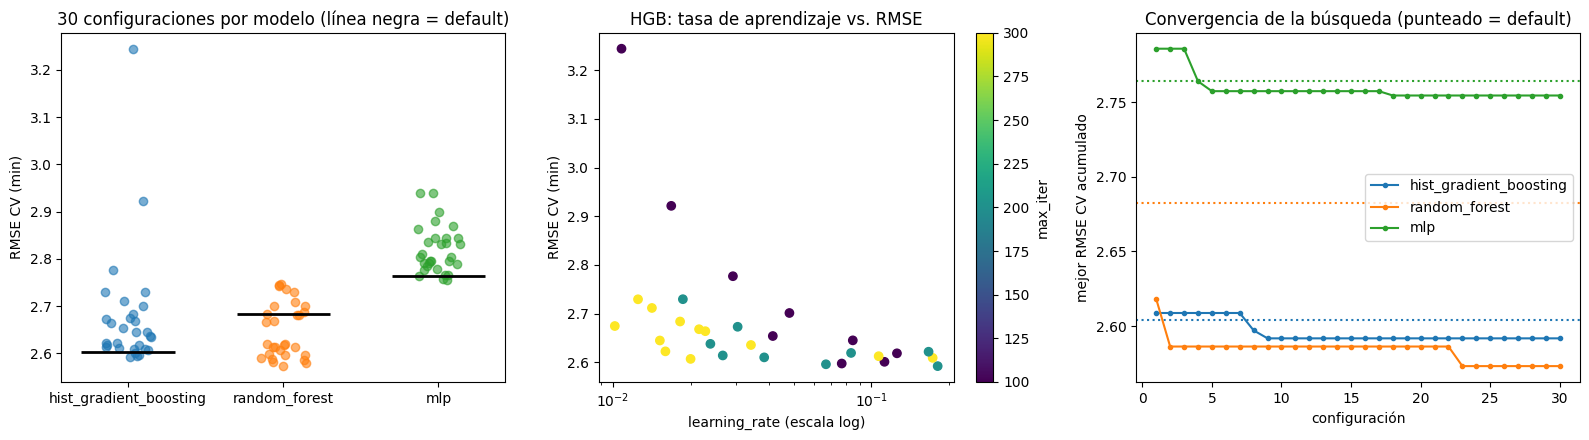

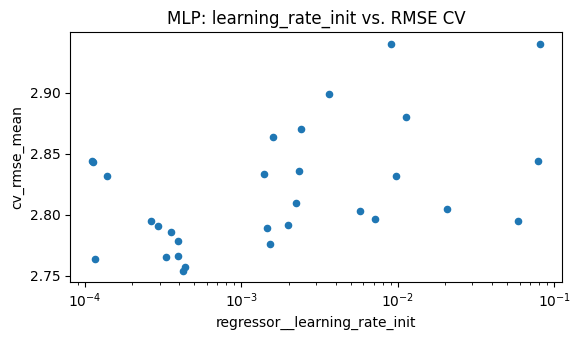

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for i, family in enumerate(top_families):
    rows = tuning_table[tuning_table["family"] == family].sort_values("configuration")
    axes[0].scatter(np.full(len(rows), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(rows)), rows["cv_rmse_mean"], alpha=0.6)
    axes[0].hlines(defaults.loc[family, "cv_rmse_mean"], i - 0.3, i + 0.3, color="black", lw=2)
    axes[2].plot(rows["configuration"], rows["cv_rmse_mean"].cummin(), marker=".", label=family)
    axes[2].axhline(defaults.loc[family, "cv_rmse_mean"], ls=":", color=axes[2].lines[-1].get_color())
axes[0].set_xticks(range(len(top_families)), top_families)
axes[0].set(ylabel="RMSE CV (min)", title="30 configuraciones por modelo (línea negra = default)")

lr = tuning_table[tuning_table["family"] == "hist_gradient_boosting"]
sc = axes[1].scatter(lr["regressor__learning_rate"].astype(float), lr["cv_rmse_mean"], c=lr["regressor__max_iter"].astype(float), cmap="viridis")
axes[1].set_xscale("log")
axes[1].set(xlabel="learning_rate (escala log)", ylabel="RMSE CV (min)", title="HGB: tasa de aprendizaje vs. RMSE")
fig.colorbar(sc, ax=axes[1], label="max_iter")
axes[2].set(xlabel="configuración", ylabel="mejor RMSE CV acumulado", title="Convergencia de la búsqueda (punteado = default)")
axes[2].legend()
plt.tight_layout()
plt.show()

mlp = tuning_table[tuning_table["family"] == "mlp"].astype({"regressor__learning_rate_init": float})
if len(mlp):
    ax = mlp.plot.scatter(x="regressor__learning_rate_init", y="cv_rmse_mean", logx=True, figsize=(6, 3.5), title="MLP: learning_rate_init vs. RMSE CV")
    plt.tight_layout()
    plt.show()

**Lectura.** En los tres modelos la mejora del tuning es **menor que la desviación entre pliegues** (≈0,20–0,25 min): HGB mejora 0,012 min (0,5%), Random Forest 0,109 min (4,1%) y MLP 0,010 min (0,4%). Con la regla del enunciado, **ninguna mejora es concluyente**: los valores por defecto ya eran competitivos.

El tuning sí cambia el perfil de error. HGB elige una tasa alta (`learning_rate≈0,18`, 200 iteraciones) y su brecha train–CV **sube** de 0,47 a 0,64 min: gana algo de ajuste a costa de más sobreajuste. Random Forest limita `max_depth=24` y usa `max_features=0,5`, pero la brecha sigue en ≈1,46 min. El MLP con tasa baja (`learning_rate_init≈4e-4`) reduce su brecha a 0,24 min sin mejorar el CV. Como el mejor de 30 configuraciones se elige con el mismo CV, su RMSE es ligeramente optimista; por eso la comparación final se confirma una sola vez en el holdout.